In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [4]:
K = tf.keras
L = tf.keras.layers

In [6]:
#dataset
kw = dict(image_size=(128,128),batch_size=32,validation_split=0.2,seed=42)
tr = K.utils.image_dataset_from_directory("Intel Image Classification",subset="training",**kw)
va = K.utils.image_dataset_from_directory("Intel Image Classification",subset="validation",**kw)

Found 12632 files belonging to 6 classes.
Using 10106 files for training.
Found 12632 files belonging to 6 classes.
Using 2526 files for validation.


In [7]:
#load base model
base = K.applications.VGG16(include_top=False,input_shape=(128,128,3),weights="vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")
base.trainable = False
model = K.Sequential([L.Input((128,128,3)), L.Lambda(K.applications.vgg16.preprocess_input), base, L.GlobalAveragePooling2D(),L.Dense(256,activation="relu"), L.Dropout(0.3), L.Dense(len(va.class_names),activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │           1,542 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,847,558 (56.64 MB)

 Trainable params: 132,870 (519.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [8]:
#compile
model.compile(optimizer=K.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(tr, validation_data=va, epochs=4)

Epoch 1/4
316/316 ━━━━━━━━━━━━━━━━━━━━ 162s 509ms/step - accuracy: 0.7820 - loss: 1.3526 - val_accuracy: 0.8939 - val_loss: 0.3461
Epoch 2/4
316/316 ━━━━━━━━━━━━━━━━━━━━ 159s 503ms/step - accuracy: 0.9044 - loss: 0.2994 - val_accuracy: 0.9117 - val_loss: 0.3001
Epoch 3/4
316/316 ━━━━━━━━━━━━━━━━━━━━ 162s 514ms/step - accuracy: 0.9221 - loss: 0.2099 - val_accuracy: 0.9082 - val_loss: 0.3107
Epoch 4/4
316/316 ━━━━━━━━━━━━━━━━━━━━ 164s 518ms/step - accuracy: 0.9353 - loss: 0.1732 - val_accuracy: 0.9070 - val_loss: 0.3195


In [9]:
#evaluate
model.evaluate(va)
X, y = zip(*va.as_numpy_iterator())
X, y = np.concatenate(X), np.concatenate(y) 
pred = model.predict(X).argmax(1)
print(classification_report(y, pred, target_names=va.class_names))

79/79 ━━━━━━━━━━━━━━━━━━━━ 32s 402ms/step - accuracy: 0.9097 - loss: 0.3053
79/79 ━━━━━━━━━━━━━━━━━━━━ 32s 401ms/step
              precision    recall  f1-score   support

   buildings       0.94      0.86      0.90       385
      forest       0.99      0.99      0.99       390
     glacier       0.87      0.83      0.85       424
    mountain       0.85      0.88      0.86       471
         sea       0.94      0.95      0.94       403
      street       0.88      0.95      0.91       453

    accuracy                           0.91      2526
   macro avg       0.91      0.91      0.91      2526
weighted avg       0.91      0.91      0.91      2526



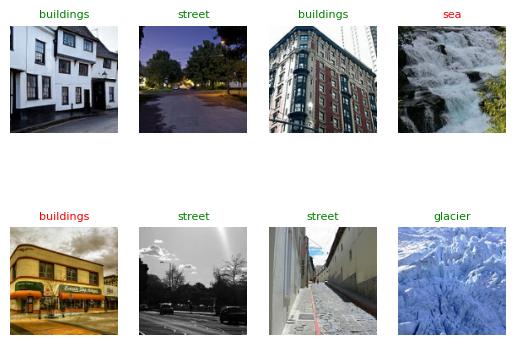

In [10]:
#plot
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(X[i].astype("uint8")); plt.axis("off")
    plt.title(va.class_names[pred[i]], color="g" if pred[i] == y[i] else "r", fontsize=8)
plt.show()

In [11]:
#fine tune
base.trainable = True
for l in base.layers[:-4]:
    l.trainable = False
model.compile(optimizer=K.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(tr, validation_data=va, epochs=2)
print(model.evaluate(va))

Epoch 1/2
316/316 ━━━━━━━━━━━━━━━━━━━━ 184s 580ms/step - accuracy: 0.9469 - loss: 0.1377 - val_accuracy: 0.9169 - val_loss: 0.3113
Epoch 2/2
316/316 ━━━━━━━━━━━━━━━━━━━━ 187s 593ms/step - accuracy: 0.9674 - loss: 0.0906 - val_accuracy: 0.9153 - val_loss: 0.3178
79/79 ━━━━━━━━━━━━━━━━━━━━ 34s 425ms/step - accuracy: 0.9222 - loss: 0.2874
[0.3177538514137268, 0.9152810573577881]


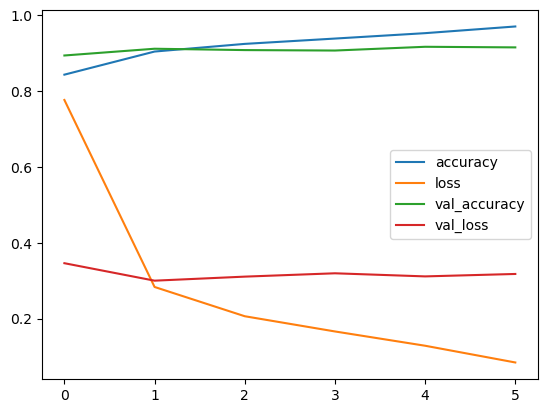

In [12]:
#compare
pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True).plot()
plt.show()